# Aprendizaje por refuerzos — Clase 2: aproximación de funciones y DQN

Sutton & Barto, *Reinforcement Learning: An Introduction*, 2ª edición, secciones 6.4–6.5, capítulo 9, sección 11.3 y sección 16.5. Russell & Norvig, *Artificial Intelligence: A Modern Approach*, 4ª edición, sección 23.4. Mnih et al. (2015), *Human-level control through deep reinforcement learning*.

En la clase anterior el agente guardaba lo que aprendía en una **tabla**: un valor $Q(s,a)$ para cada par de estado y acción. En esta clase vamos a:

1. Repasar Q-learning en un problema con riesgo (CliffWalking) y compararlo con SARSA.
2. Ver qué pasa cuando los estados son tantos (o infinitos) que no entran en una tabla.
3. Reemplazar la tabla por una red neuronal y llegar a **DQN** (*Deep Q-Network*), con sus dos ideas clave: la **memoria de repetición** y la **red objetivo**.

In [1]:
import random
from collections import defaultdict, deque

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

# Con redes tan chicas, un solo hilo es más rápido que varios.
torch.set_num_threads(1)

def promedio_movil(x, n=20):
    # Promedio de las últimas n posiciones, para suavizar las curvas de aprendizaje.
    x = np.asarray(x, dtype=float)
    return np.array([x[max(0, i - n + 1):i + 1].mean() for i in range(len(x))])

# REPASO: Q-LEARNING EN CLIFFWALKING

El entorno que vamos a usar para este ejemplo es CliffWalking-v1, que representa un escenario simple pero muy ilustrativo:

- El agente comienza en la esquina inferior izquierda de un tablero.
- La meta se encuentra en la esquina inferior derecha.
- Entre el inicio y la meta hay un "acantilado" que termina el episodio si el agente cae en él, con una penalización fuerte.
- Cada paso que el agente da tiene un costo pequeño, por lo que queremos que aprenda a llegar a la meta rápidamente y evitando el acantilado.

**Objetivo del ejemplo**

Aprender una **política óptima** que permita al agente:

1. Alcanzar la meta con la mayor recompensa posible.
2. Evitar caer en el acantilado.
3. Balancear exploración (probar nuevas acciones) y explotación (usar lo que ya sabe) usando la estrategia ε-greedy.

**Para esto haremos los siguientes pasos:**

- Inicializaremos una Q-Table para representar el conocimiento del agente.
- Implementaremos una política ε-greedy para seleccionar acciones.
- Aplicaremos la regla de actualización de Q-Learning basada en el error temporal-diferencial (TD error):

$$
Q(s, a) \gets Q(s, a) + \alpha \Big[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \Big]
$$

Al final, evaluaremos cómo se comporta el agente entrenado y verificaremos si ha aprendido a evitar el acantilado mientras alcanza la meta.


In [2]:
# Q-Learning en CliffWalking-v1
# ---------------------------------
# Objetivo: Aprender una política óptima para llegar a la meta evitando el acantilado
# usando el algoritmo de aprendizaje por refuerzo Q-Learning.

import gymnasium as gym
import numpy as np
from collections import defaultdict


# Hiperparámetros
ALPHA = 0.1        # Tasa de aprendizaje (qué tanto se actualiza la Q-table)
GAMMA = 0.99       # Factor de descuento (importancia de recompensas futuras)
EPSILON = 0.1      # Probabilidad de exploración (ε-greedy)
EPISODES = 1500     # Cantidad de episodios de entrenamiento

# Crear entorno
# render_mode="ansi" dibuja el tablero como texto
env = gym.make("CliffWalking-v1", render_mode="ansi")

# Q-Table representada como diccionario: Q[state][action]
Q = defaultdict(lambda: np.zeros(env.action_space.n))

def epsilon_greedy_policy(state):
    """Selecciona una acción según la política ε-greedy."""
    if np.random.random() < EPSILON:
        return env.action_space.sample()  # acción aleatoria (exploración)
    else:
        return np.argmax(Q[state])        # acción con mayor valor Q (explotación)

# Entrenamiento
for episode in range(EPISODES):
    state, _ = env.reset()
    done = False

    while not done:
        # 1️⃣ Elegir acción según política ε-greedy
        action = epsilon_greedy_policy(state)

        # 2️⃣ Ejecutar la acción en el entorno
        next_state, reward, terminated, truncated, _ = env.step(action)

        # 3️⃣ Calcular el valor objetivo (TD target)
        #    Q-Learning es off-policy: usa la mejor acción futura conocida (greedy)
        best_next_action = np.argmax(Q[next_state])
        td_target = reward + GAMMA * Q[next_state][best_next_action]

        # 4️⃣ Calcular el error temporal (TD error)
        td_error = td_target - Q[state][action]

        # 5️⃣ Actualizar la Q-Table
        Q[state][action] += ALPHA * td_error

        # 6️⃣ Moverse al siguiente estado
        state = next_state
        done = terminated or truncated

# ------------------------------------------------------------
# EVALUACIÓN DEL AGENTE ENTRENADO
# ------------------------------------------------------------
state, _ = env.reset()
print(env.render())

done = False
total_reward = 0

print("\n--- EJECUCIÓN DEL AGENTE ENTRENADO ---")
while not done:
    action = np.argmax(Q[state])  # acción con mayor Q conocida
    next_state, reward, terminated, truncated, _ = env.step(action)
    total_reward += reward
    print(env.render())  # muestra el entorno paso a paso en consola
    state = next_state
    done = terminated or truncated

print(f"\nRecompensa total del episodio: {total_reward}")
env.close()


o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
x  C  C  C  C  C  C  C  C  C  C  T



--- EJECUCIÓN DEL AGENTE ENTRENADO ---
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
x  o  o  o  o  o  o  o  o  o  o  o
o  C  C  C  C  C  C  C  C  C  C  T


o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  x  o  o  o  o  o  o  o  o  o  o
o  C  C  C  C  C  C  C  C  C  C  T


o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  x  o  o  o  o  o  o  o  o  o
o  C  C  C  C  C  C  C  C  C  C  T


o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  x  o  o  o  o  o  o  o  o
o  C  C  C  C  C  C  C  C  C  C  T


o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  x  o  o  o  o  o  o  o
o  C  C  C  C  C  C  C  C  C  C  T


o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  x  o  o  o  o  o  o
o  

En el tablero, `x` es el agente, `C` el acantilado y `T` la meta. El agente entrenado camina **pegado al acantilado**: es el camino más corto, y por lo tanto el óptimo, si nunca se equivoca.

## SARSA: aprender la política que se sigue

### Teoría:
SARSA es un algoritmo de diferencias temporales muy parecido a Q-learning. La diferencia está en el valor que usa para el estado siguiente: en lugar del máximo, usa el valor de la acción $A_{t+1}$ que el agente **efectivamente va a tomar**:

$$
Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \left[ R_{t+1} + \gamma Q(S_{t+1}, A_{t+1}) - Q(S_t, A_t) \right]
$$

El nombre viene de los cinco elementos que usa cada actualización: $(S_t, A_t, R_{t+1}, S_{t+1}, A_{t+1})$.

- **Q-learning es *off-policy***: elige las acciones con ε-greedy, pero aprende los valores de la política greedy (la del $\max$). Aprende $q_*$ aunque explore.
- **SARSA es *on-policy***: aprende los valores de la misma política ε-greedy con la que se mueve, incluidos los errores que comete al explorar.

En CliffWalking esto hace una diferencia importante (Sutton & Barto, ejemplo 6.6). Con ε = 0.1, cada tanto el agente da un paso al azar. Si camina pegado al acantilado, ese paso al azar puede tirarlo abajo (−100). Q-learning ignora ese riesgo, porque evalúa la política greedy, que nunca se equivoca. SARSA lo tiene en cuenta.

### Simulación:
Entrenamos los dos algoritmos con los mismos parámetros y promediamos 10 corridas de cada uno.

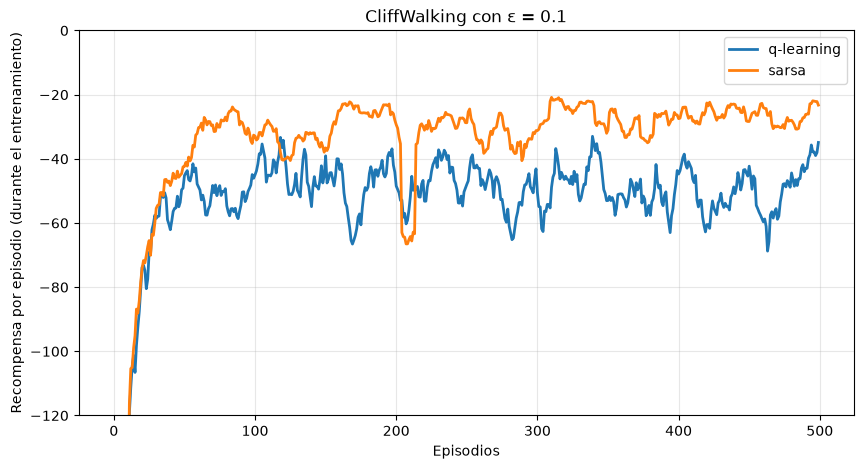

q-learning: recompensa promedio en los últimos 100 episodios = -49.5
     sarsa: recompensa promedio en los últimos 100 episodios = -26.2


In [3]:
def entrenar_cliff(metodo, episodios=500, alpha=0.5, gamma=1.0, epsilon=0.1, semilla=0):
    rng = np.random.default_rng(semilla)
    env = gym.make("CliffWalking-v1")
    Q = np.zeros((env.observation_space.n, env.action_space.n))

    def elegir(s):
        # ε-greedy, desempatando al azar entre las acciones de mayor valor
        if rng.random() < epsilon:
            return int(rng.integers(env.action_space.n))
        return int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))

    recompensas = []
    for ep in range(episodios):
        s, _ = env.reset(seed=semilla * 1000 + ep)
        a = elegir(s)
        total, fin = 0, False
        while not fin:
            s2, r, terminado, truncado, _ = env.step(a)
            a2 = elegir(s2)                      # la acción que de verdad se va a tomar
            if metodo == "q-learning":
                siguiente = Q[s2].max()          # la mejor acción, aunque no se tome
            else:
                siguiente = Q[s2, a2]            # SARSA: la acción que se toma
            objetivo = r + gamma * (0 if terminado else siguiente)
            Q[s, a] += alpha * (objetivo - Q[s, a])
            s, a = s2, a2
            total += r
            fin = terminado or truncado
        recompensas.append(total)
    return np.array(recompensas), Q

corridas = 10
curvas = {}
tablas = {}
for metodo in ("q-learning", "sarsa"):
    resultados = [entrenar_cliff(metodo, semilla=k) for k in range(corridas)]
    curvas[metodo] = np.mean([r for r, _ in resultados], axis=0)
    tablas[metodo] = resultados[0][1]

plt.figure(figsize=(10, 5))
for metodo, curva in curvas.items():
    plt.plot(promedio_movil(curva, 10), label=metodo, linewidth=2)
plt.ylim(-120, 0)
plt.xlabel("Episodios")
plt.ylabel("Recompensa por episodio (durante el entrenamiento)")
plt.title("CliffWalking con ε = 0.1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for metodo, curva in curvas.items():
    print(f"{metodo:>10}: recompensa promedio en los últimos 100 episodios = {curva[-100:].mean():.1f}")

Veamos el camino que sigue cada uno con su política greedy, es decir, una vez que deja de explorar:

In [4]:
FLECHAS = ["↑", "→", "↓", "←"]   # el orden de las acciones en CliffWalking

def dibujar_camino(Q):
    env = gym.make("CliffWalking-v1")
    s, _ = env.reset()
    camino = {s: FLECHAS[int(np.argmax(Q[s]))]}
    for _ in range(100):
        s, _, terminado, truncado, _ = env.step(int(np.argmax(Q[s])))
        if terminado or truncado:
            break
        camino[s] = FLECHAS[int(np.argmax(Q[s]))]
    for fila in range(4):
        celdas = []
        for col in range(12):
            s = fila * 12 + col
            if fila == 3 and 0 < col < 11:
                celdas.append("C")
            elif s == 47:
                celdas.append("T")
            else:
                celdas.append(camino.get(s, "·"))
        print(" ".join(celdas))

for metodo, Q in tablas.items():
    print(metodo)
    dibujar_camino(Q)
    print()

q-learning
· · · · · · · · · · · ·
· · · · · · · · · · · ·
→ → → → → → → → → → → ↓
↑ C C C C C C C C C C T

sarsa
→ → → → → → → → → → ↓ ·
↑ · · · · · · · · · → ↓
↑ · · · · · · · · · · ↓
↑ C C C C C C C C C C T



### Preguntas:
¿Cuál de los dos aprende el camino óptimo? ¿Cuál obtiene más recompensa **mientras aprende**? ¿Por qué no es el mismo?

¿Qué pasaría con SARSA si ε se fuera achicando hasta llegar a cero?

## Exploración decreciente

Explorar mucho es útil al principio, cuando el agente no sabe nada, pero molesta al final, cuando ya conoce buenas acciones. Una solución muy usada es empezar con un ε alto y **reducirlo con el tiempo**. Por ejemplo, de forma lineal durante los primeros $T$ pasos:

$$
\varepsilon_t = \max\left(\varepsilon_{\text{fin}},\; \varepsilon_{\text{ini}} - (\varepsilon_{\text{ini}} - \varepsilon_{\text{fin}}) \frac{t}{T}\right)
$$

Con $\varepsilon_{\text{ini}} = 1$ el agente arranca eligiendo todo al azar, y termina explorando solo una fracción $\varepsilon_{\text{fin}}$ de las veces (por ejemplo, 0.05). Lo vamos a usar en DQN.

# CUANDO LOS ESTADOS NO ENTRAN EN UNA TABLA

Los problemas que vimos hasta ahora tenían pocos estados: 25 en la grilla, 48 en CliffWalking, 16 en FrozenLake. Pero en la mayoría de los problemas interesantes la cantidad de estados es enorme:

- El backgammon tiene alrededor de $10^{20}$ estados.
- En un juego de Atari el estado es la imagen de la pantalla: con 84×84 píxeles y 256 tonos de gris hay $256^{84 \cdot 84}$ imágenes posibles.
- Cuando el estado se describe con números reales (una posición, una velocidad), directamente hay **infinitos** estados.

Con una tabla hay dos problemas. El primero es de memoria: no entra. El segundo es más grave: **la tabla no generaliza**. Cada casilla se aprende por separado, así que lo aprendido en un estado no sirve para otro estado parecido. Con tantos estados, la mayoría no se visita nunca o se visita muy pocas veces.

## Ejemplo: CartPole

En CartPole hay que mantener un palo en equilibrio sobre un carrito, moviendo el carrito a la izquierda o a la derecha.

- **Estado**: 4 números reales: posición del carrito, velocidad del carrito, ángulo del palo y velocidad angular del palo.
- **Acciones**: empujar el carrito a la izquierda (0) o a la derecha (1).
- **Recompensa**: +1 por cada paso en que el palo sigue en pie.
- **Fin del episodio**: si el palo se inclina más de 12°, si el carrito se sale de la pista o si se llega a 500 pasos.

El retorno máximo, entonces, es 500.

Espacio de estados: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Espacio de acciones: Discrete(2)
Estado inicial: [ 0.01369617 -0.02302133 -0.04590265 -0.04834723]


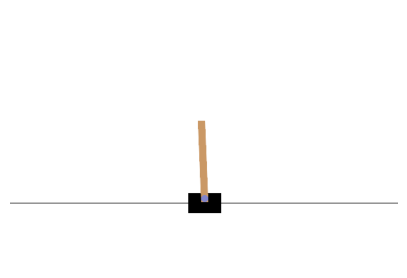

Política al azar: el palo dura en promedio 22.9 pasos


In [5]:
env = gym.make("CartPole-v1", render_mode="rgb_array")
estado, _ = env.reset(seed=0)
print("Espacio de estados:", env.observation_space)
print("Espacio de acciones:", env.action_space)
print("Estado inicial:", estado)

plt.figure(figsize=(5, 3.5))
plt.imshow(env.render())
plt.axis("off")
plt.show()

# Una política al azar, como referencia
duraciones = []
for ep in range(100):
    env.reset(seed=ep)
    total, fin = 0, False
    while not fin:
        _, r, terminado, truncado, _ = env.step(env.action_space.sample())
        total += r
        fin = terminado or truncado
    duraciones.append(total)
print(f"Política al azar: el palo dura en promedio {np.mean(duraciones):.1f} pasos")

## Primer intento: discretizar

Una forma de seguir usando una tabla es **discretizar**: dividir el rango de cada variable en intervalos (*bins*) y tratar cada combinación de intervalos como un estado. Con 6 intervalos por variable hay $6^4 = 1296$ estados; con 10, hay $10^4 = 10000$.

Probemos Q-learning con las dos discretizaciones:

6 intervalos: 315 estados visitados de 1296, recompensa promedio en los últimos 100 episodios = 140


10 intervalos: 842 estados visitados de 10000, recompensa promedio en los últimos 100 episodios = 160


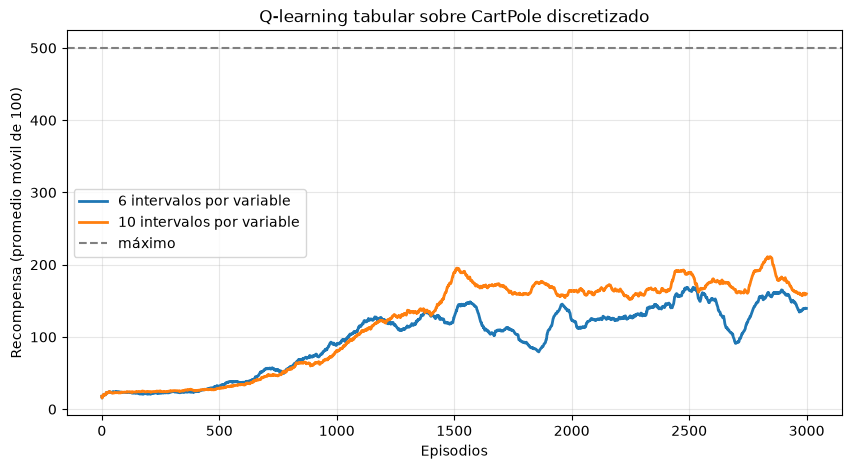

In [6]:
LIMITES = np.array([2.4, 3.0, 0.21, 3.5])   # rango que consideramos para cada variable

def discretizar(estado, bins):
    estado = np.clip(estado, -LIMITES, LIMITES)
    indices = ((estado + LIMITES) / (2 * LIMITES) * bins).astype(int)
    return tuple(np.minimum(indices, bins - 1))

def q_learning_discreto(bins, episodios=3000, alpha=0.1, gamma=0.99, semilla=0):
    rng = np.random.default_rng(semilla)
    bins = np.array(bins)
    env = gym.make("CartPole-v1")
    Q = defaultdict(lambda: np.zeros(2))
    recompensas = []
    for ep in range(episodios):
        epsilon = max(0.01, 1.0 - ep / (episodios / 2))      # ε decreciente
        s, _ = env.reset(seed=semilla * 100_000 + ep)
        d = discretizar(s, bins)
        total, fin = 0, False
        while not fin:
            a = int(rng.integers(2)) if rng.random() < epsilon else int(np.argmax(Q[d]))
            s2, r, terminado, truncado, _ = env.step(a)
            d2 = discretizar(s2, bins)
            objetivo = r + gamma * (0 if terminado else Q[d2].max())
            Q[d][a] += alpha * (objetivo - Q[d][a])
            d, total, fin = d2, total + r, terminado or truncado
        recompensas.append(total)
    return np.array(recompensas), Q

plt.figure(figsize=(10, 5))
for b in (6, 10):
    recompensas, Q = q_learning_discreto([b] * 4)
    plt.plot(promedio_movil(recompensas, 100), label=f"{b} intervalos por variable", linewidth=2)
    print(f"{b} intervalos: {len(Q)} estados visitados de {b**4}, "
          f"recompensa promedio en los últimos 100 episodios = {recompensas[-100:].mean():.0f}")
plt.axhline(500, color="gray", linestyle="--", label="máximo")
plt.xlabel("Episodios")
plt.ylabel("Recompensa (promedio móvil de 100)")
plt.title("Q-learning tabular sobre CartPole discretizado")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Preguntas:
El agente aprende algo, pero después de 3000 episodios sigue lejos de 500. ¿Por qué no alcanza con poner más intervalos?

Dos estados con un ángulo de 0.050 y de 0.051 radianes caen a veces en intervalos distintos. ¿Qué aprende la tabla sobre uno cuando visita el otro?

# APROXIMACIÓN DE FUNCIONES

### Teoría:
La idea es reemplazar la tabla por una **función con parámetros** $\mathbf{w}$ que aproxime los valores de acción:

$$
\hat{q}(s, a; \mathbf{w}) \approx q_*(s, a)
$$

La función tiene muchos menos parámetros que estados, así que no puede guardar un valor independiente para cada uno. Eso es justamente lo que queremos: al ajustar $\mathbf{w}$ con la experiencia de un estado, cambian también los valores de los estados **parecidos**. La función **generaliza**.

### Aprender como un problema de regresión
En Q-learning, cada transición $(s, a, r, s')$ nos da un **objetivo** para $Q(s,a)$:

$$
y = r + \gamma \max_{a'} \hat{q}(s', a'; \mathbf{w})
$$

Queremos que $\hat{q}(s,a;\mathbf{w})$ se acerque a $y$, igual que en un problema de regresión. Usamos el error cuadrático como función de pérdida:

$$
L(\mathbf{w}) = \big( y - \hat{q}(s,a;\mathbf{w}) \big)^2
$$

y damos un paso de descenso por el gradiente:

$$
\mathbf{w} \leftarrow \mathbf{w} + \alpha \big[ y - \hat{q}(s,a;\mathbf{w}) \big] \nabla_{\mathbf{w}} \hat{q}(s,a;\mathbf{w})
$$

El término entre corchetes es el mismo **error TD** de Q-learning. De hecho, la tabla es un caso particular: un parámetro por cada par $(s,a)$, con gradiente 1 para la casilla visitada y 0 para el resto.

Un detalle: el objetivo $y$ también depende de $\mathbf{w}$, pero no lo derivamos; lo tratamos como si fuera un dato fijo. Por eso a este método se lo llama de **semi-gradiente**.

## Una red neuronal como aproximador

La función más simple es lineal en alguna representación del estado, pero es poco expresiva. En DQN se usa una **red neuronal**. Hay dos formas de armarla:

- Entrada $(s, a)$ y una salida $\hat{q}(s,a)$.
- **Entrada $s$ y una salida por cada acción**: $\hat{q}(s, a_1), \dots, \hat{q}(s, a_n)$.

Se usa la segunda, porque con una sola pasada por la red se obtienen los valores de todas las acciones, que es justo lo que hace falta para calcular el $\max$ del objetivo y para elegir la acción greedy.

Para CartPole alcanza con una red chica: 4 entradas, dos capas ocultas de 128 neuronas y 2 salidas.

In [7]:
def crear_red():
    return nn.Sequential(
        nn.Linear(4, 128), nn.ReLU(),
        nn.Linear(128, 128), nn.ReLU(),
        nn.Linear(128, 2),          # una salida por acción
    )

red = crear_red()
estado = torch.as_tensor(gym.make("CartPole-v1").reset(seed=0)[0])
print("Q(s, ·) =", red(estado).detach().numpy())
print("Parámetros de la red:", sum(p.numel() for p in red.parameters()))

Q(s, ·) = [-0.07908017 -0.02412491]
Parámetros de la red: 17410


# Q-LEARNING CON UNA RED: PRIMER INTENTO

La forma más directa de usar la red es reemplazar la tabla en el algoritmo de siempre: en cada paso, el agente toma una acción, observa la transición y da **un paso de gradiente con esa sola transición**, calculando el objetivo con la misma red.

Para comparar todo lo que sigue en las mismas condiciones, entrenamos siempre durante **100.000 pasos** con ε decreciente (de 1 a 0.05 en los primeros 10.000 pasos). Como función de pérdida usamos la **pérdida de Huber**, una variante del error cuadrático que se explica más adelante, en DQN.

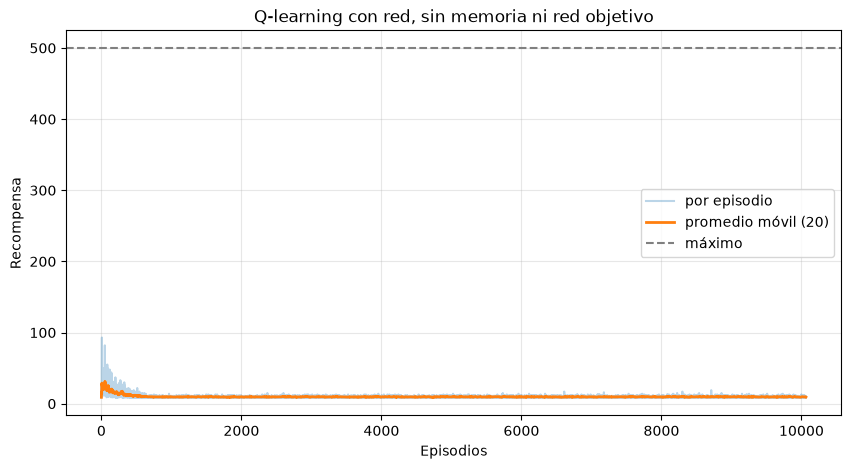

Episodios jugados: 10065, recompensa promedio en los últimos 20: 9


In [8]:
PASOS = 100_000
GAMMA = 0.99

def epsilon_lineal(paso, inicial=1.0, final=0.05, pasos_decaimiento=10_000):
    return max(final, inicial - (inicial - final) * paso / pasos_decaimiento)

def q_learning_con_red(pasos_totales=PASOS, alpha=5e-4, semilla=0):
    random.seed(semilla); np.random.seed(semilla); torch.manual_seed(semilla)
    env = gym.make("CartPole-v1")
    red = crear_red()
    optimizador = torch.optim.Adam(red.parameters(), lr=alpha)

    recompensas, paso, episodio = [], 0, 0
    while paso < pasos_totales:
        s, _ = env.reset(seed=semilla * 10_000 + episodio)
        total, fin = 0, False
        while not fin:
            # 1. Elegir acción con ε-greedy sobre la red
            if random.random() < epsilon_lineal(paso):
                a = random.randrange(env.action_space.n)
            else:
                with torch.no_grad():
                    a = int(red(torch.as_tensor(s)).argmax())

            # 2. Ejecutar la acción
            s2, r, terminado, truncado, _ = env.step(a)

            # 3. Objetivo calculado con la misma red (sin derivar: semi-gradiente)
            with torch.no_grad():
                y = r + GAMMA * (0.0 if terminado else red(torch.as_tensor(s2)).max().item())

            # 4. Un paso de gradiente con esta única transición
            q_sa = red(torch.as_tensor(s))[a]
            perdida = nn.functional.smooth_l1_loss(q_sa, torch.tensor(y))   # pérdida de Huber
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()

            s, total, paso = s2, total + r, paso + 1
            fin = terminado or truncado
        recompensas.append(total)
        episodio += 1
    return np.array(recompensas)

recompensas_ingenuo = q_learning_con_red()

plt.figure(figsize=(10, 5))
plt.plot(recompensas_ingenuo, alpha=0.3, label="por episodio")
plt.plot(promedio_movil(recompensas_ingenuo), linewidth=2, label="promedio móvil (20)")
plt.axhline(500, color="gray", linestyle="--", label="máximo")
plt.xlabel("Episodios")
plt.ylabel("Recompensa")
plt.title("Q-learning con red, sin memoria ni red objetivo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print(f"Episodios jugados: {len(recompensas_ingenuo)}, "
      f"recompensa promedio en los últimos 20: {recompensas_ingenuo[-20:].mean():.0f}")

El agente no aprende. Peor todavía: después de los primeros episodios termina **peor que la política al azar**, empujando el carrito casi siempre hacia el mismo lado, y el palo cae a los pocos pasos.

## ¿Por qué falla?

Hay dos problemas, y ninguno aparecía con la tabla:

1. **Las muestras están correlacionadas.** El descenso por el gradiente supone que los ejemplos de entrenamiento son independientes. Pero acá entrenamos con transiciones consecutivas, que son casi iguales entre sí (el palo se mueve muy poco de un paso al otro). La red se ajusta demasiado a la situación del momento y, como generaliza, al hacerlo modifica los valores de todos los demás estados.
2. **El objetivo se mueve.** El objetivo $y$ se calcula con la misma red que estamos entrenando. Cada paso de gradiente cambia $\mathbf{w}$, y con eso cambia el objetivo: es como intentar alcanzar algo que se aleja cada vez que nos acercamos.

Sutton & Barto (sección 11.3) llaman **tríada mortal** (*deadly triad*) a la combinación de tres ingredientes que, juntos, pueden hacer que el aprendizaje sea inestable o directamente diverja:

- aproximación de funciones,
- *bootstrapping* (el objetivo usa estimaciones, como $\max_{a'} \hat{q}(s',a')$),
- aprendizaje *off-policy*.

Q-learning con una red tiene los tres. DQN (Mnih et al., 2015) no elimina la tríada, pero agrega dos ideas que hacen el entrenamiento mucho más estable: la memoria de repetición y la red objetivo.

# MEMORIA DE REPETICIÓN

### Teoría:
En lugar de aprender de la última transición y descartarla, el agente guarda cada transición $(s, a, r, s', \text{terminado})$ en una **memoria de repetición** (*experience replay*) de capacidad fija $N$. Cuando se llena, las más viejas se van descartando.

En cada paso, en vez de entrenar con la transición recién vivida, se toma un **minibatch** de $B$ transiciones **al azar** de la memoria y se da un paso de gradiente con el promedio de sus errores.

Esto tiene dos ventajas:

- **Rompe la correlación**: las transiciones de un minibatch vienen de momentos distintos del entrenamiento.
- **Reusa la experiencia**: cada transición se usa muchas veces, no una sola.

Esto funciona porque Q-learning es *off-policy*: aprende $q_*$ a partir de transiciones generadas por cualquier política, incluso por versiones viejas del propio agente. SARSA, que aprende el valor de la política actual, no podría usar transiciones viejas así nomás.

In [9]:
class MemoriaRepeticion:
    def __init__(self, capacidad):
        self.datos = deque(maxlen=capacidad)    # al llenarse, descarta las más viejas

    def guardar(self, s, a, r, s2, terminado):
        self.datos.append((s, a, r, s2, terminado))

    def muestrear(self, tamano):
        lote = random.sample(self.datos, tamano)
        s, a, r, s2, terminado = map(np.array, zip(*lote))
        return (torch.as_tensor(s), torch.as_tensor(a), torch.as_tensor(r, dtype=torch.float32),
                torch.as_tensor(s2), torch.as_tensor(terminado, dtype=torch.float32))

    def __len__(self):
        return len(self.datos)

# Ejemplo: guardamos 5 transiciones al azar y muestreamos 3
memoria = MemoriaRepeticion(capacidad=1000)
env = gym.make("CartPole-v1")
s, _ = env.reset(seed=0)
for _ in range(5):
    a = env.action_space.sample()
    s2, r, terminado, _, _ = env.step(a)
    memoria.guardar(s, a, r, s2, terminado)
    s = s2
s, a, r, s2, terminado = memoria.muestrear(3)
print("acciones del minibatch:", a)
print("estados del minibatch:\n", s)

acciones del minibatch: tensor([1, 1, 1])
estados del minibatch:
 tensor([[ 0.0167,  0.3685, -0.0540, -0.6622],
        [ 0.0353,  0.3702, -0.0866, -0.7006],
        [ 0.0132,  0.1727, -0.0469, -0.3552]])


# RED OBJETIVO

### Teoría:
Para que el objetivo no se mueva en cada paso, DQN usa una **segunda red**, la **red objetivo**, con pesos $\mathbf{w}^-$. Es una copia de la red principal que se deja **congelada** y solo se actualiza cada $C$ pasos, copiando los pesos: $\mathbf{w}^- \leftarrow \mathbf{w}$.

El objetivo se calcula con la red objetivo:

$$
y = r + \gamma \max_{a'} \hat{q}(s', a'; \mathbf{w}^-)
$$

Durante $C$ pasos el objetivo queda fijo, y el problema se parece mucho más a una regresión común. Juntando las dos ideas, la función de pérdida que minimiza DQN es el promedio sobre transiciones sacadas de la memoria $D$:

$$
L(\mathbf{w}) = \mathbb{E}_{(s,a,r,s') \sim D} \Big[ \big( r + \gamma \max_{a'} \hat{q}(s', a'; \mathbf{w}^-) - \hat{q}(s, a; \mathbf{w}) \big)^2 \Big]
$$

# DQN

### Algoritmo
(Mnih et al., 2015)

1. Inicializar la memoria $D$ con capacidad $N$, la red $\hat{q}$ con pesos $\mathbf{w}$ al azar y la red objetivo con $\mathbf{w}^- = \mathbf{w}$.
2. En cada paso:
    1. Elegir la acción $a$ con ε-greedy sobre $\hat{q}(s, \cdot\,; \mathbf{w})$.
    2. Ejecutarla, observar $r$ y $s'$, y guardar $(s, a, r, s', \text{terminado})$ en $D$.
    3. Muestrear un minibatch de $D$ y calcular, para cada transición, $y_j = r_j$ si $s'_j$ es terminal, o $y_j = r_j + \gamma \max_{a'} \hat{q}(s'_j, a'; \mathbf{w}^-)$ si no.
    4. Dar un paso de gradiente sobre $\big(y_j - \hat{q}(s_j, a_j; \mathbf{w})\big)^2$.
    5. Cada $C$ pasos, copiar $\mathbf{w}^- \leftarrow \mathbf{w}$.

Dos detalles de la implementación:

- Se empieza a entrenar cuando la memoria ya tiene algunas transiciones (acá, 1000).
- Como en el paper, se usa la **pérdida de Huber** en vez del error cuadrático: es igual al cuadrado para errores chicos, pero crece en forma lineal para errores grandes. Así un objetivo muy desviado no produce un gradiente enorme.

La función tiene dos opciones para poder apagar cada idea por separado y ver qué aporta. Sin memoria, el minibatch es solo la última transición. Sin red objetivo, $y$ se calcula con la misma red.

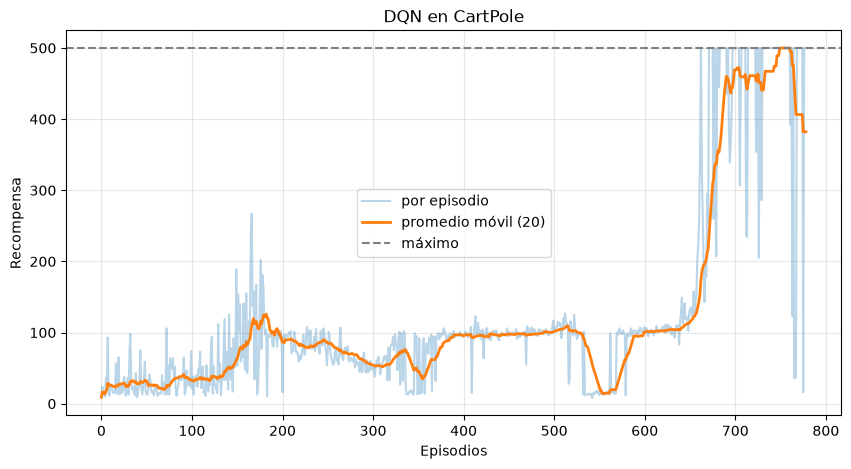

Episodios jugados: 779, recompensa promedio en los últimos 20: 382


In [10]:
def dqn(usar_memoria=True, usar_red_objetivo=True, pasos_totales=PASOS, semilla=0,
        alpha=5e-4, capacidad=10_000, tamano_lote=64, C=200, inicio=1000):
    random.seed(semilla); np.random.seed(semilla); torch.manual_seed(semilla)
    env = gym.make("CartPole-v1")
    red = crear_red()
    red_objetivo = crear_red()
    red_objetivo.load_state_dict(red.state_dict())          # w⁻ = w
    optimizador = torch.optim.Adam(red.parameters(), lr=alpha)
    memoria = MemoriaRepeticion(capacidad if usar_memoria else 1)

    recompensas, paso, episodio = [], 0, 0
    while paso < pasos_totales:
        s, _ = env.reset(seed=semilla * 10_000 + episodio)
        total, fin = 0, False
        while not fin:
            # 1. Acción ε-greedy
            if random.random() < epsilon_lineal(paso):
                a = random.randrange(env.action_space.n)
            else:
                with torch.no_grad():
                    a = int(red(torch.as_tensor(s)).argmax())

            # 2. Ejecutar y guardar la transición
            s2, r, terminado, truncado, _ = env.step(a)
            memoria.guardar(s, a, r, s2, terminado)
            s, total, paso = s2, total + r, paso + 1
            fin = terminado or truncado

            if usar_memoria and len(memoria) < inicio:
                continue

            # 3. Minibatch y objetivo
            S, A, R, S2, T = memoria.muestrear(tamano_lote if usar_memoria else 1)
            with torch.no_grad():
                red_y = red_objetivo if usar_red_objetivo else red
                y = R + GAMMA * (1 - T) * red_y(S2).max(dim=1).values

            # 4. Paso de gradiente sobre Q(s, a) de las acciones tomadas
            q_sa = red(S).gather(1, A.unsqueeze(1)).squeeze(1)
            perdida = nn.functional.smooth_l1_loss(q_sa, y)    # pérdida de Huber
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()

            # 5. Cada C pasos, actualizar la red objetivo
            if usar_red_objetivo and paso % C == 0:
                red_objetivo.load_state_dict(red.state_dict())
        recompensas.append(total)
        episodio += 1
    return np.array(recompensas), red

recompensas_dqn, red_dqn = dqn()

plt.figure(figsize=(10, 5))
plt.plot(recompensas_dqn, alpha=0.3, label="por episodio")
plt.plot(promedio_movil(recompensas_dqn), linewidth=2, label="promedio móvil (20)")
plt.axhline(500, color="gray", linestyle="--", label="máximo")
plt.xlabel("Episodios")
plt.ylabel("Recompensa")
plt.title("DQN en CartPole")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print(f"Episodios jugados: {len(recompensas_dqn)}, "
      f"recompensa promedio en los últimos 20: {recompensas_dqn[-20:].mean():.0f}")

Evaluemos la política aprendida sin explorar (ε = 0) durante 20 episodios nuevos:

Recompensa en evaluación: 500 ± 0 (máximo posible: 500)


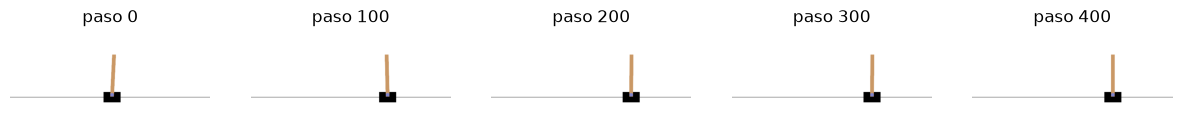

In [11]:
def evaluar(red, episodios=20, semilla=1234):
    env = gym.make("CartPole-v1")
    totales = []
    for ep in range(episodios):
        s, _ = env.reset(seed=semilla + ep)
        total, fin = 0, False
        while not fin:
            with torch.no_grad():
                a = int(red(torch.as_tensor(s)).argmax())
            s, r, terminado, truncado, _ = env.step(a)
            total += r
            fin = terminado or truncado
        totales.append(total)
    return np.array(totales)

totales = evaluar(red_dqn)
print(f"Recompensa en evaluación: {totales.mean():.0f} ± {totales.std():.0f} (máximo posible: 500)")

# Algunos cuadros de un episodio con la política aprendida
env = gym.make("CartPole-v1", render_mode="rgb_array")
s, _ = env.reset(seed=1234)
cuadros = []
for t in range(500):
    if t % 100 == 0:
        cuadros.append(env.render())
    with torch.no_grad():
        s, _, terminado, truncado, _ = env.step(int(red_dqn(torch.as_tensor(s)).argmax()))
    if terminado or truncado:
        break

fig, axes = plt.subplots(1, len(cuadros), figsize=(3 * len(cuadros), 2.4))
for t, (ax, cuadro) in enumerate(zip(np.atleast_1d(axes), cuadros)):
    ax.imshow(cuadro[100:320])
    ax.set_title(f"paso {100 * t}")
    ax.axis("off")
plt.show()

## ¿Qué aporta cada pieza?

Entrenamos las cuatro combinaciones (con y sin memoria, con y sin red objetivo), tres veces cada una con distintas semillas, siempre con 100.000 pasos. Lleva alrededor de media hora.

Mnih et al. hicieron este mismo experimento con 5 juegos de Atari: cada idea por separado mejoraba el resultado, y las dos juntas lo mejoraban muchísimo.

 sin memoria, sin red objetivo: últimos 20 episodios = 10 (por semilla: 9, 10, 9)


 sin memoria, con red objetivo: últimos 20 episodios = 104 (por semilla: 35, 71, 207)


 con memoria, sin red objetivo: últimos 20 episodios = 10 (por semilla: 10, 10, 10)


             DQN (con las dos): últimos 20 episodios = 427 (por semilla: 382, 456, 442)


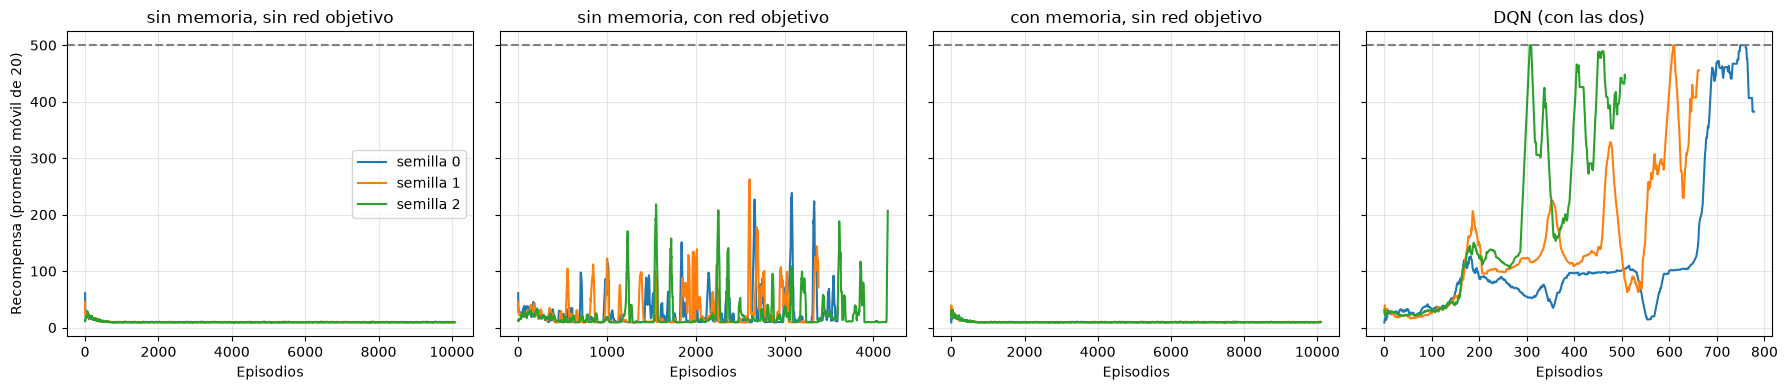

In [12]:
variantes = {
    "sin memoria, sin red objetivo": dict(usar_memoria=False, usar_red_objetivo=False),
    "sin memoria, con red objetivo": dict(usar_memoria=False, usar_red_objetivo=True),
    "con memoria, sin red objetivo": dict(usar_memoria=True, usar_red_objetivo=False),
    "DQN (con las dos)": dict(usar_memoria=True, usar_red_objetivo=True),
}
semillas = (0, 1, 2)

resultados = {}
for nombre, opciones in variantes.items():
    resultados[nombre] = [dqn(semilla=k, **opciones)[0] for k in semillas]
    finales = [r[-20:].mean() for r in resultados[nombre]]
    print(f"{nombre:>30}: últimos 20 episodios = {np.mean(finales):.0f} "
          f"(por semilla: {', '.join(f'{f:.0f}' for f in finales)})")

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (nombre, curvas) in zip(axes, resultados.items()):
    for k, recompensas in zip(semillas, curvas):
        ax.plot(promedio_movil(recompensas), label=f"semilla {k}")
    ax.axhline(500, color="gray", linestyle="--")
    ax.set_title(nombre)
    ax.set_xlabel("Episodios")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Recompensa (promedio móvil de 20)")
axes[0].legend()
plt.tight_layout()
plt.show()

### Preguntas:
¿Cuál de las dos ideas tiene más efecto por sí sola? ¿Por qué tiene sentido que la red objetivo sola ayude poco si las muestras siguen correlacionadas?

Las variantes que no aprenden juegan muchos más episodios en los mismos 100.000 pasos. ¿Por qué?

Mnih et al. encontraron que, en Atari, la memoria sola ya mejoraba el resultado. Acá, sin red objetivo, la memoria sola no alcanza. ¿Qué diferencias entre los dos problemas podrían explicarlo? Pensá en la cantidad de pasos de entrenamiento y en el tamaño de la red.

Aun con DQN, la curva a veces cae después de haber llegado a 500. ¿Qué parte de la tríada mortal sigue presente?

# MÁS ALLÁ DE DQN

DQN se presentó para jugar juegos de Atari a partir de la imagen de la pantalla (Mnih et al., 2015). La red recibía los últimos 4 cuadros del juego (para poder percibir movimiento), los procesaba con capas convolucionales y tenía una salida por cada botón del joystick. Con **la misma arquitectura y los mismos hiperparámetros** aprendió 49 juegos distintos, cada uno después de unos 50 millones de cuadros (unos 38 días de juego). Superó al jugador humano en 22 juegos, y en 29 de los 46 comparados alcanzó al menos el 75 % de su puntaje (Sutton & Barto, sección 16.5).

Desde entonces se propusieron muchas mejoras. La más simple es **Double DQN** (van Hasselt et al., 2016). El $\max$ del objetivo tiende a sobreestimar los valores, porque elige la acción y la evalúa con las mismas estimaciones ruidosas (es el **sesgo de maximización**, Sutton & Barto, sección 6.7). Double DQN separa las dos cosas: elige la acción con la red principal y la evalúa con la red objetivo.

$$
y = r + \gamma\, \hat{q}\big(s', \arg\max_{a'} \hat{q}(s', a'; \mathbf{w}); \mathbf{w}^-\big)
$$